# Geometry-only collapse clustering

This is an unsupervised exploration. RAPID timing response is excluded when fitting clusters and is used only afterward to interpret whether geometric groups correspond to distinct response patterns.

In [5]:
from pathlib import Path
from datetime import datetime, timezone
import subprocess
import sys
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / 'RAPID').exists():
    REPO_ROOT = REPO_ROOT.parents[1]
OUTPUT_ROOT = Path('/Volumes/PhD/river_hierarchy/network_variants/output')
EXAMPLE_IDS = ['02', '03', '05', '11','13','15', '21', '56']  # edit when more real-network outputs are available
RUN_DIR = REPO_ROOT / 'RAPID' / 'classification' / 'results' / f"clustering-notebook-{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}"


In [6]:
command = [sys.executable, str(REPO_ROOT / 'RAPID/classification/train_rapid_geometry_clustering.py'),
           '--output-root', str(OUTPUT_ROOT), '--results-dir', str(RUN_DIR),
           '--example-ids', *EXAMPLE_IDS]
subprocess.run(command, cwd=REPO_ROOT, check=True)


Wrote /Users/6256481/Code/river-hierarchy/RAPID/classification/results/clustering-notebook-20260824T134556Z
Wrote a clustering review table; inspect supported candidates rather than treating any single metric as a winner.


CompletedProcess(args=['/opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python', '/Users/6256481/Code/river-hierarchy/RAPID/classification/train_rapid_geometry_clustering.py', '--output-root', '/Volumes/PhD/river_hierarchy/network_variants/output', '--results-dir', '/Users/6256481/Code/river-hierarchy/RAPID/classification/results/clustering-notebook-20260824T134556Z', '--example-ids', '02', '03', '05', '11', '13', '15', '21', '56'], returncode=0)

In [7]:
summary = pd.read_csv(RUN_DIR / 'clustering_quality_summary.csv')
display(summary)
valid = summary.loc[summary.valid_exploratory_solution].dropna(subset=['silhouette'])
best = valid.iloc[0]['algorithm']
print('Highest-silhouette supported candidate:', best)


,algorithm,n_clusters,noise_fraction,smallest_cluster_size,min_cluster_example_support,valid_exploratory_solution,outlier_candidate,silhouette,calinski_harabasz,davies_bouldin,posthoc_response_mean_range_pct_points,review_status
0,agglomerative_ward_k2,2,0.000000,37,7,True,False,0.454432,94.199283,0.880732,0.188178,regular-structure candidate — inspect stabilit...
1,kmeans_k2,2,0.000000,35,6,True,False,0.463383,94.525926,0.843025,0.197462,regular-structure candidate — inspect stabilit...
2,agglomerative_average_k2,2,0.000000,1,1,False,False,0.865565,84.145278,0.097198,0.145839,unsupported partition — insufficient cluster s...
3,agglomerative_average_k3,3,0.000000,1,1,False,True,0.572179,90.632132,0.481790,2.637852,outlier candidate — validate its geometry and ...
4,agglomerative_average_k4,4,0.000000,1,1,False,True,0.507524,63.095338,0.458237,2.923636,outlier candidate — validate its geometry and ...
5,agglomerative_average_k5,5,0.000000,1,1,False,True,0.500133,110.421923,0.541970,2.923636,outlier candidate — validate its geometry and ...
6,agglomerative_average_k6,6,0.000000,1,1,False,True,0.480739,91.947782,0.619635,3.873516,outlier candidate — validate its geometry and ...
7,agglomerative_ward_k3,3,0.000000,1,1,False,True,0.465782,118.733603,0.605476,0.188698,outlier candidate — validate its geometry and ...
8,agglomerative_ward_k4,4,0.000000,1,1,False,True,0.422831,152.411618,0.669084,0.374395,outlier candidate — validate its geometry and ...
9,agglomerative_ward_k5,5,0.000000,1,1,False,True,0.529805,205.734373,0.729663,0.577226,outlier candidate — validate its geometry and ...


Highest-silhouette supported candidate: agglomerative_ward_k2


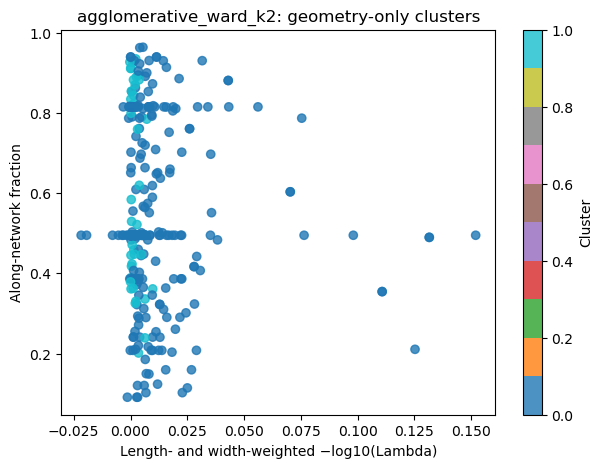

,n,response_mean,response_median,examples
cluster,,,,
0,318,-0.306584,-0.070771,8
1,37,-0.118406,0.000000,7


In [8]:
assignments = pd.read_csv(RUN_DIR / 'cluster_assignments.csv')
plot_df = assignments.loc[assignments.algorithm.eq(best)].copy()
fig, ax = plt.subplots(figsize=(7, 5))
scatter = ax.scatter(plot_df.len_fraction_width_weighted_log_lambda, plot_df.along_network_frac, c=plot_df.cluster, cmap='tab10', alpha=.8)
ax.set(xlabel='Length- and width-weighted −log10(Lambda)', ylabel='Along-network fraction', title=f'{best}: geometry-only clusters')
fig.colorbar(scatter, ax=ax, label='Cluster')
plt.show()
display(plot_df.groupby('cluster').agg(n=('state_id','size'), response_mean=('lag_to_inflow_peak_pct_shift_vs_base','mean'), response_median=('lag_to_inflow_peak_pct_shift_vs_base','median'), examples=('example_id','nunique')))
